In [280]:
import pandas as pd
import datetime as dt
import seaborn as sns
import matplotlib.pyplot as plt
base_vendas = pd.read_excel("Datasets/base_vendas_ecommerce_etl.xlsx")

In [281]:
base_vendas["nome_cliente"] = base_vendas["nome_cliente"].str.title()
base_vendas["nome_cliente"] = base_vendas["nome_cliente"].str.strip().str.replace(r"\s+", " ", regex=True)

base_vendas["metodo_pagamento"] = base_vendas["metodo_pagamento"].str.lower()

In [282]:
def limpar_metodo_pagamento(pagamento):
    credito =["cartao de credito", "cartão de crédito", "credito"]
    debito=["cartão de débito", "debito"]
    boleto=["boleto", "boleto bancario"]
    
    if not isinstance(pagamento, str):
        return "Não Informado"
    
    if any(metodo in pagamento for metodo in boleto):
            return "Boleto"
    elif any(metodo in pagamento for metodo in credito):
            return "Crédito"
    elif any(metodo in pagamento for metodo in debito):
                return "Débito"
    elif "pix" in pagamento:
        return "Pix"
    else:
        return pagamento
    
base_vendas["metodo_pagamento"] = base_vendas["metodo_pagamento"].apply(limpar_metodo_pagamento)
base_vendas.groupby("metodo_pagamento").count()

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,estado_cliente,status_pedido
metodo_pagamento,,,,,,,,,,
Boleto,2019,2019,2019,2019,2019,1958,2019,1888,1956,2019
Crédito,3055,3055,3055,3055,3055,2979,3055,2892,2967,3055
Débito,2040,2040,2040,2040,2040,1963,2040,1904,1979,2040
Não Informado,421,421,421,421,421,406,421,398,407,421
Pix,2965,2965,2965,2965,2965,2873,2965,2771,2874,2965


In [283]:
base_vendas['estado_cliente'] = base_vendas['estado_cliente'].str.upper()
base_vendas['estado_cliente'] = base_vendas['estado_cliente'].replace({
    'SP': 'São Paulo',
    'RJ': 'Rio de Janeiro',
    'MG': 'Minas Gerais',
    'ES': 'Espírito Santo',
    'BA': 'Bahia',
    'RS': 'Rio Grande do Sul',
    'PR': 'Paraná',
    'SC': 'Santa Catarina',
    'NaN': 'Não Informado'
    })

base_vendas['estado_cliente'] = base_vendas['estado_cliente'].fillna("Não Informado")


In [284]:
base_vendas['estado_cliente'] = base_vendas['estado_cliente'].str.title()
base_vendas.groupby("estado_cliente").count()

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,status_pedido
estado_cliente,,,,,,,,,,
Bahia,1650,1650,1650,1650,1650,1610,1650,1557,1650,1650
Minas Gerais,1550,1550,1550,1550,1550,1501,1550,1455,1550,1550
Não Informado,317,317,317,317,317,308,317,296,317,317
Paraná,1626,1626,1626,1626,1626,1570,1626,1523,1626,1626
Rio De Janeiro,1545,1545,1545,1545,1545,1497,1545,1449,1545,1545
Rio Grande Do Sul,730,730,730,730,730,707,730,678,730,730
Santa Catarina,765,765,765,765,765,738,765,716,765,765
São Paulo,2317,2317,2317,2317,2317,2248,2317,2179,2317,2317


In [285]:
base_vendas.head(20)

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,estado_cliente,status_pedido
0,ORD-15118,2024-10-30 05:31:00,Gabriel Alves,Livro Data Science Guide,Livros,2.0,90,180.00,Crédito,São Paulo,Em Processamento
1,ORD-18931,2024-03-14 15:24:00,Carlos Eduardo Santos,Teclado Mecânico,Acessórios,2.0,350,700.00,Crédito,Rio Grande Do Sul,Em Processamento
2,ORD-18515,2024-07-19 10:09:00,Maria Oliveira,Cadeira Ergonômica,Móveis,5.0,850,4250.00,Boleto,São Paulo,Em Processamento
3,ORD-17282,2025-03-14 22:58:00,Rodrigo Ferreira,Fone de Ouvido Bluetooth,Acessórios,5.0,200,1000.00,Crédito,Bahia,Concluído
4,ORD-17623,2024-10-06 14:30:00,Ana Silva,Aspirador de Pó,Eletrodomésticos,5.0,300,1500.00,Boleto,Rio Grande Do Sul,Cancelado
5,ORD-16029,2024-12-17 19:01:00,Beatriz Costa,Smartphone X,Eletrônicos,2.0,2500,5000.00,Crédito,Bahia,Pendente
6,ORD-13329,2024-11-29 21:47:00,Aline Pereira,Mesa para Escritório,Móveis,4.0,600,2400.00,Boleto,São Paulo,Em Processamento
7,ORD-18934,2024-01-31 22:35:00,Beatriz Costa,Cafeteira Expressa,Eletrodomésticos,2.0,400,800.00,Boleto,São Paulo,Em Processamento
8,ORD-13879,2025-01-04 01:41:00,Rafael Barbosa,Notebook Pro,Eletrônicos,1.0,4500,-4500.00,Boleto,São Paulo,Concluído
9,ORD-13781,2024-05-05 08:22:00,Carlos Eduardo Santos,Aspirador de Pó,Eletrodomésticos,4.0,300,1242.94,Crédito,Minas Gerais,Pendente


In [286]:
base_vendas['preco_unitario'] = base_vendas['preco_unitario'].abs()
base_vendas['valor_total'] = base_vendas['valor_total'].abs()
base_vendas['quantidade'] = base_vendas['quantidade'].abs()

base_vendas

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,estado_cliente,status_pedido
0,ORD-15118,2024-10-30 05:31:00,Gabriel Alves,Livro Data Science Guide,Livros,2.0,90,180.0,Crédito,São Paulo,Em Processamento
1,ORD-18931,2024-03-14 15:24:00,Carlos Eduardo Santos,Teclado Mecânico,Acessórios,2.0,350,700.0,Crédito,Rio Grande Do Sul,Em Processamento
2,ORD-18515,2024-07-19 10:09:00,Maria Oliveira,Cadeira Ergonômica,Móveis,5.0,850,4250.0,Boleto,São Paulo,Em Processamento
3,ORD-17282,2025-03-14 22:58:00,Rodrigo Ferreira,Fone de Ouvido Bluetooth,Acessórios,5.0,200,1000.0,Crédito,Bahia,Concluído
4,ORD-17623,2024-10-06 14:30:00,Ana Silva,Aspirador de Pó,Eletrodomésticos,5.0,300,1500.0,Boleto,Rio Grande Do Sul,Cancelado
...,...,...,...,...,...,...,...,...,...,...,...
10495,ORD-15734,2024-08-20 15:04:00,Thiago Carvalho,Cafeteira Expressa,Eletrodomésticos,4.0,400,1600.0,Pix,Rio De Janeiro,Cancelado
10496,ORD-15191,2024-09-21 02:28:00,Gabriel Alves,Monitor 27 Polegadas,Eletrônicos,4.0,1200,4800.0,Crédito,Rio De Janeiro,Pendente
10497,ORD-15390,2024-01-06 15:06:00,Beatriz Costa,Notebook Pro,Eletrônicos,3.0,4500,13500.0,Pix,São Paulo,Pendente
10498,ORD-10860,2025-02-25 17:50:00,Thiago Carvalho,Cadeira Ergonômica,Móveis,5.0,850,4250.0,Boleto,Rio De Janeiro,Em Processamento


In [287]:
base_vendas['preco_unitario'] = base_vendas['preco_unitario'].fillna("0")
base_vendas['valor_total'] = base_vendas['valor_total'].fillna("0")
base_vendas['quantidade'] = base_vendas['quantidade'].fillna("0")

base_vendas

C:\Users\senaij01\AppData\Local\Temp\ipykernel_18836\1601967623.py:2: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  base_vendas['valor_total'] = base_vendas['valor_total'].fillna("0")
C:\Users\senaij01\AppData\Local\Temp\ipykernel_18836\1601967623.py:3: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  base_vendas['quantidade'] = base_vendas['quantidade'].fillna("0")


,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,estado_cliente,status_pedido
0,ORD-15118,2024-10-30 05:31:00,Gabriel Alves,Livro Data Science Guide,Livros,2.0,90,180.0,Crédito,São Paulo,Em Processamento
1,ORD-18931,2024-03-14 15:24:00,Carlos Eduardo Santos,Teclado Mecânico,Acessórios,2.0,350,700.0,Crédito,Rio Grande Do Sul,Em Processamento
2,ORD-18515,2024-07-19 10:09:00,Maria Oliveira,Cadeira Ergonômica,Móveis,5.0,850,4250.0,Boleto,São Paulo,Em Processamento
3,ORD-17282,2025-03-14 22:58:00,Rodrigo Ferreira,Fone de Ouvido Bluetooth,Acessórios,5.0,200,1000.0,Crédito,Bahia,Concluído
4,ORD-17623,2024-10-06 14:30:00,Ana Silva,Aspirador de Pó,Eletrodomésticos,5.0,300,1500.0,Boleto,Rio Grande Do Sul,Cancelado
...,...,...,...,...,...,...,...,...,...,...,...
10495,ORD-15734,2024-08-20 15:04:00,Thiago Carvalho,Cafeteira Expressa,Eletrodomésticos,4.0,400,1600.0,Pix,Rio De Janeiro,Cancelado
10496,ORD-15191,2024-09-21 02:28:00,Gabriel Alves,Monitor 27 Polegadas,Eletrônicos,4.0,1200,4800.0,Crédito,Rio De Janeiro,Pendente
10497,ORD-15390,2024-01-06 15:06:00,Beatriz Costa,Notebook Pro,Eletrônicos,3.0,4500,13500.0,Pix,São Paulo,Pendente
10498,ORD-10860,2025-02-25 17:50:00,Thiago Carvalho,Cadeira Ergonômica,Móveis,5.0,850,4250.0,Boleto,Rio De Janeiro,Em Processamento


In [288]:
vendas = base_vendas[base_vendas["status_pedido"].isin(["Concluido", "Em Processamento"])]


In [289]:
def calcular_valor_total(valor):
    if valor["quantidade"] == 0:
        return 0
    else:
        return valor["preco_unitario"] * valor["quantidade"]
    
base_vendas['valor_total'] = base_vendas.apply(calcular_valor_total, axis=1)

In [290]:
def verificar(linha):
    if linha['valor_total'] == 0 or linha['quantidade'] == 0:
        return False
    return True

base_vendas = base_vendas[base_vendas.apply(verificar, axis=1)]

In [291]:
base_vendas['data_pedido'] = pd.to_datetime(base_vendas['data_pedido'])
base_vendas['mes'] = base_vendas['data_pedido'].dt.month
base_vendas['mes'] = base_vendas['mes'].replace({
    1: 'Janeiro',
    2: 'Fevereiro',
    3: 'Março',
    4: 'Abril',
    5: 'Maio',
    6: 'Junho',
    7: 'Julho',
    8: 'Agosto',
    9: 'Setembro',
    10: 'Outubro',
    11: 'Novembro',
    12: 'Dezembro'
    })

base_vendas

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,estado_cliente,status_pedido,mes
0,ORD-15118,2024-10-30 05:31:00,Gabriel Alves,Livro Data Science Guide,Livros,2.0,90,180.0,Crédito,São Paulo,Em Processamento,Outubro
1,ORD-18931,2024-03-14 15:24:00,Carlos Eduardo Santos,Teclado Mecânico,Acessórios,2.0,350,700.0,Crédito,Rio Grande Do Sul,Em Processamento,Março
2,ORD-18515,2024-07-19 10:09:00,Maria Oliveira,Cadeira Ergonômica,Móveis,5.0,850,4250.0,Boleto,São Paulo,Em Processamento,Julho
3,ORD-17282,2025-03-14 22:58:00,Rodrigo Ferreira,Fone de Ouvido Bluetooth,Acessórios,5.0,200,1000.0,Crédito,Bahia,Concluído,Março
4,ORD-17623,2024-10-06 14:30:00,Ana Silva,Aspirador de Pó,Eletrodomésticos,5.0,300,1500.0,Boleto,Rio Grande Do Sul,Cancelado,Outubro
...,...,...,...,...,...,...,...,...,...,...,...,...
10495,ORD-15734,2024-08-20 15:04:00,Thiago Carvalho,Cafeteira Expressa,Eletrodomésticos,4.0,400,1600.0,Pix,Rio De Janeiro,Cancelado,Agosto
10496,ORD-15191,2024-09-21 02:28:00,Gabriel Alves,Monitor 27 Polegadas,Eletrônicos,4.0,1200,4800.0,Crédito,Rio De Janeiro,Pendente,Setembro
10497,ORD-15390,2024-01-06 15:06:00,Beatriz Costa,Notebook Pro,Eletrônicos,3.0,4500,13500.0,Pix,São Paulo,Pendente,Janeiro
10498,ORD-10860,2025-02-25 17:50:00,Thiago Carvalho,Cadeira Ergonômica,Móveis,5.0,850,4250.0,Boleto,Rio De Janeiro,Em Processamento,Fevereiro


In [292]:
base_vendas['data_pedido'] = pd.to_datetime(base_vendas['data_pedido'])

base_vendas['data'] = base_vendas['data_pedido'].dt.strftime('%d/%m/%Y')
base_vendas['hora'] = base_vendas['data_pedido'].dt.time



In [293]:
base_vendas['ano'] = base_vendas['data_pedido'].dt.year

contagem_meses_ano = base_vendas.groupby("ano")['mes'].value_counts().reset_index(name="quantidade")
meses_ordem = ["Janeiro", "Fevereiro", "Março", "Abril", "Maio", "Junho", "Julho", "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"]
contagem_meses_ano["mes"] = pd.Categorical(contagem_meses_ano["mes"], categories=meses_ordem, ordered=True)

In [294]:
base_vendas = base_vendas.drop(columns=['data_pedido'])
base_vendas

,id_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,estado_cliente,status_pedido,mes,data,hora,ano
0,ORD-15118,Gabriel Alves,Livro Data Science Guide,Livros,2.0,90,180.0,Crédito,São Paulo,Em Processamento,Outubro,30/10/2024,05:31:00,2024
1,ORD-18931,Carlos Eduardo Santos,Teclado Mecânico,Acessórios,2.0,350,700.0,Crédito,Rio Grande Do Sul,Em Processamento,Março,14/03/2024,15:24:00,2024
2,ORD-18515,Maria Oliveira,Cadeira Ergonômica,Móveis,5.0,850,4250.0,Boleto,São Paulo,Em Processamento,Julho,19/07/2024,10:09:00,2024
3,ORD-17282,Rodrigo Ferreira,Fone de Ouvido Bluetooth,Acessórios,5.0,200,1000.0,Crédito,Bahia,Concluído,Março,14/03/2025,22:58:00,2025
4,ORD-17623,Ana Silva,Aspirador de Pó,Eletrodomésticos,5.0,300,1500.0,Boleto,Rio Grande Do Sul,Cancelado,Outubro,06/10/2024,14:30:00,2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10495,ORD-15734,Thiago Carvalho,Cafeteira Expressa,Eletrodomésticos,4.0,400,1600.0,Pix,Rio De Janeiro,Cancelado,Agosto,20/08/2024,15:04:00,2024
10496,ORD-15191,Gabriel Alves,Monitor 27 Polegadas,Eletrônicos,4.0,1200,4800.0,Crédito,Rio De Janeiro,Pendente,Setembro,21/09/2024,02:28:00,2024
10497,ORD-15390,Beatriz Costa,Notebook Pro,Eletrônicos,3.0,4500,13500.0,Pix,São Paulo,Pendente,Janeiro,06/01/2024,15:06:00,2024
10498,ORD-10860,Thiago Carvalho,Cadeira Ergonômica,Móveis,5.0,850,4250.0,Boleto,Rio De Janeiro,Em Processamento,Fevereiro,25/02/2025,17:50:00,2025


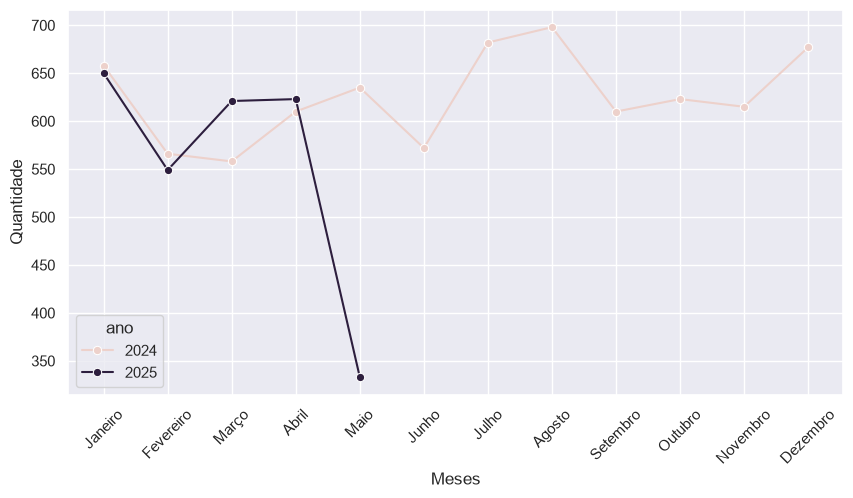

In [295]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
sns.lineplot(data=contagem_meses_ano, x="mes", y="quantidade", hue="ano", marker="o")
plt.xticks(rotation=45)
plt.xlabel("Meses")
plt.ylabel("Quantidade")
plt.show()

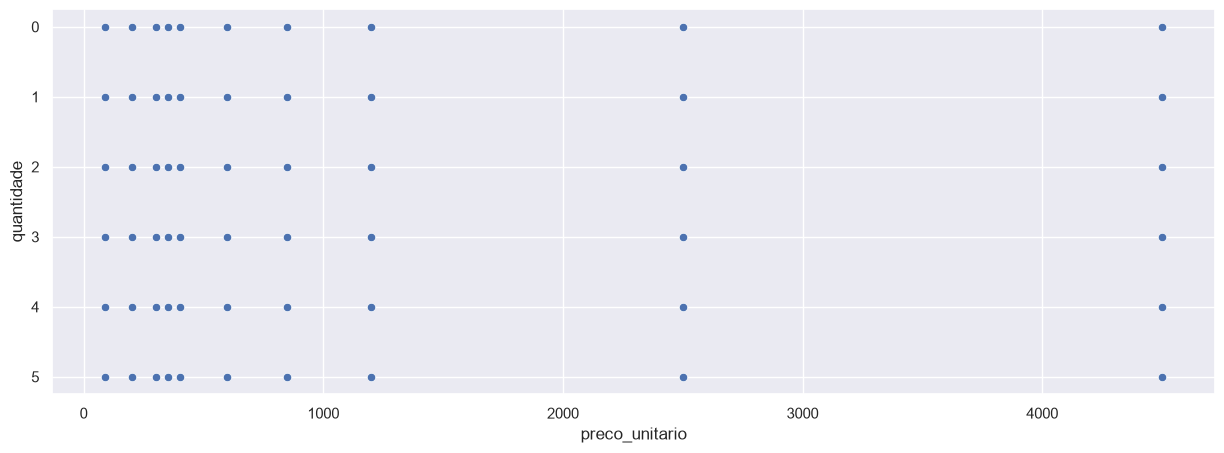

In [296]:
plt.figure(figsize=(15,5))
sns.scatterplot(data=base_vendas, x="preco_unitario", y="quantidade")
plt.show()

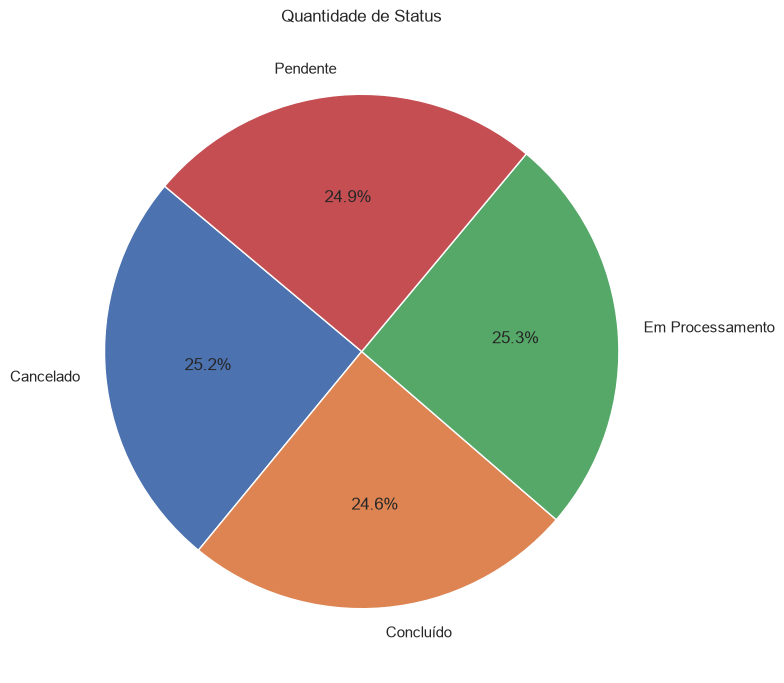

In [300]:
contagem_status = base_vendas.groupby("status_pedido").size().reset_index(name="quantidade")

plt.figure(figsize=(8,8))

plt.pie(contagem_status["quantidade"], 
        labels = contagem_status["status_pedido"],
        autopct = "%1.1f%%",
        startangle = 140
        )
plt.title("Quantidade de Status")
plt.tight_layout()
plt.show()